# PlayStation Launch Price Analysis
### Comparing Each Console's Nominal and Inflation-Adjusted Prices

## Project Overview

This project analyzes the U.S. launch prices of the PlayStation 1
through PlayStation 5 and adjusts historical prices for inflation
using Consumer Price Index (CPI-U) data from the U.S. Bureau of
Labor Statistics.

The purpose of the analysis is to determine whether PlayStation
consoles have actually become more expensive over time after
accounting for changes in the purchasing power of the U.S. dollar.

## Research Questions

1. How have nominal PlayStation launch prices changed across generations?
2. How do historical launch prices compare when expressed in 2025 dollars?
3. Which PlayStation console had the highest and lowest real launch price?
4. How much did real launch prices change between generations?
5. Was the PS5 actually more expensive than the original PlayStation
   after accounting for inflation?

## Data Sources

Two datasets were used in this analysis:

- PlayStation console launch prices and North American release years.
- Consumer Price Index for All Urban Consumers (CPI-U), All Items,
  U.S. City Average, from the U.S. Bureau of Labor Statistics.

CPI Series ID: CUUR0000SA0

Historical prices were converted to constant 2025 U.S. dollars
using annual average CPI values.

In [1]:
print("Let's get started on PlayStation's analysis!")

Let's get started on PlayStation's analysis!


## 1. Import Libraries

In [3]:
# Import pandas for data cleaning, transformation, and analysis
import pandas as pd

# Import matplotlib for data visualization
import matplotlib.pyplot as plt

In [4]:
print(pd.__version__)

2.2.3


In [5]:
test = pd.DataFrame({
    "Console": ["PS1", "PS2", "PS3", "PS4", "PS5"],
    "Launch_Year": [1995, 2000, 2006, 2013, 2020]
})

test

,Console,Launch_Year
0,PS1,1995
1,PS2,2000
2,PS3,2006
3,PS4,2013
4,PS5,2020


## 2. Load Data

The PlayStation launch-price dataset and raw BLS CPI dataset
were imported from Excel using pandas.

In [2]:
# Store the Excel workbook for reuse throughout the notebook
excel_file = "playstation_inflation_analysis-2.xlsx"

xls = pd.ExcelFile(excel_file)

xls.sheet_names

['BLS_Raw_Data', 'Playstation_CPI']

In [4]:
# Load the PlayStation launch price dataset
ps = pd.read_excel(
    excel_file,
    sheet_name = "Playstation_CPI"
)

ps

,Console,Launch Year,Launch Price,Annual CPI,2025 CPI,Real Price (2025 USD),Real Price Change
0,PS1,1995,299.00,NaN,NaN,NaN,NaN
1,PS2,2000,299.99,NaN,NaN,NaN,NaN
2,PS3,2006,499.99,NaN,NaN,NaN,NaN
3,PS4,2013,399.99,NaN,NaN,NaN,NaN
4,PS5,2020,499.99,NaN,NaN,NaN,NaN


## 3. Data Inspection

Before transforming the datasets; I reviewed their structure,
data types, and missing values.

In [5]:
# Preview the PlayStation dataset
ps.head()

,Console,Launch Year,Launch Price,Annual CPI,2025 CPI,Real Price (2025 USD),Real Price Change
0,PS1,1995,299.00,NaN,NaN,NaN,NaN
1,PS2,2000,299.99,NaN,NaN,NaN,NaN
2,PS3,2006,499.99,NaN,NaN,NaN,NaN
3,PS4,2013,399.99,NaN,NaN,NaN,NaN
4,PS5,2020,499.99,NaN,NaN,NaN,NaN


In [6]:
# Review column names, data types, non-null counts, and dataset structure
ps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Console                5 non-null      object 
 1   Launch Year            5 non-null      int64  
 2   Launch Price           5 non-null      float64
 3   Annual CPI             0 non-null      float64
 4   2025 CPI               0 non-null      float64
 5   Real Price (2025 USD)  0 non-null      float64
 6   Real Price Change      0 non-null      float64
dtypes: float64(5), int64(1), object(1)
memory usage: 412.0+ bytes


In [7]:
# Check each column for missing values
ps.isnull().sum()

Console                  0
Launch Year              0
Launch Price             0
Annual CPI               5
2025 CPI                 5
Real Price (2025 USD)    5
Real Price Change        5
dtype: int64

In [8]:
# Generate descriptive statistics for numeric columns
ps.describe()

,Launch Year,Launch Price,Annual CPI,2025 CPI,Real Price (2025 USD),Real Price Change
count,5.000000,5.000000,0.0,0.0,0.0,0.0
mean,2006.800000,399.792000,NaN,NaN,NaN,NaN
std,9.984989,100.248172,NaN,NaN,NaN,NaN
min,1995.000000,299.000000,NaN,NaN,NaN,NaN
25%,2000.000000,299.990000,NaN,NaN,NaN,NaN
50%,2006.000000,399.990000,NaN,NaN,NaN,NaN
75%,2013.000000,499.990000,NaN,NaN,NaN,NaN
max,2020.000000,499.990000,NaN,NaN,NaN,NaN


In [19]:
bls = pd.read_excel(
    excel_file,
    sheet_name="BLS_Raw_Data"
)

In [9]:
# Load the raw BLS CPI worksheet without assigning a header
# This original file contains metadata above the data table
bls_raw = pd.read_excel(
    excel_file,
    sheet_name="BLS_Raw_Data",
    header=None
)

bls_raw.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Consumer Price Index for All Urban Consumers (...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Original Data Value,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Series Id:,CUUR0000SA0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Not Seasonally Adjusted,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Series Title:,"All items in U.S. city average, all urban cons...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Area:,U.S. city average,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Item:,All items,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Base Period:,1982-84=100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Years:,1995 to 2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Cleaning

The original BLS worksheet contains metadata above the CPI
observations. These rows were removed and only the year and
12 monthly CPI observations were retained.

In [10]:
# Reload the BLS worksheet while skipping the metadata rows
# The row containing Year, Jan, Feb, etc. becomes the header
bls = pd.read_excel(
    excel_file,
    sheet_name="BLS_Raw_Data",
    skiprows=11
)

bls.head()

,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,HALF1,HALF2
0,1995,150.3,150.9,151.4,151.9,152.2,152.5,152.5,152.9,153.2,153.7,153.6,153.5,151.5,153.2
1,1996,154.4,154.9,155.7,156.3,156.6,156.7,157.0,157.3,157.8,158.3,158.6,158.6,155.8,157.9
2,1997,159.1,159.6,160.0,160.2,160.1,160.3,160.5,160.8,161.2,161.6,161.5,161.3,159.9,161.2
3,1998,161.6,161.9,162.2,162.5,162.8,163.0,163.2,163.4,163.6,164.0,164.0,163.9,162.3,163.7
4,1999,164.3,164.5,165.0,166.2,166.2,166.2,166.7,167.1,167.9,168.2,168.3,168.3,165.4,167.8


In [11]:
bls.head()

,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,HALF1,HALF2
0,1995,150.3,150.9,151.4,151.9,152.2,152.5,152.5,152.9,153.2,153.7,153.6,153.5,151.5,153.2
1,1996,154.4,154.9,155.7,156.3,156.6,156.7,157.0,157.3,157.8,158.3,158.6,158.6,155.8,157.9
2,1997,159.1,159.6,160.0,160.2,160.1,160.3,160.5,160.8,161.2,161.6,161.5,161.3,159.9,161.2
3,1998,161.6,161.9,162.2,162.5,162.8,163.0,163.2,163.4,163.6,164.0,164.0,163.9,162.3,163.7
4,1999,164.3,164.5,165.0,166.2,166.2,166.2,166.7,167.1,167.9,168.2,168.3,168.3,165.4,167.8


In [12]:
bls.columns

Index(['Year', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep',
       'Oct', 'Nov', 'Dec', 'HALF1', 'HALF2'],
      dtype='object')

In [13]:
bls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    31 non-null     int64  
 1   Jan     31 non-null     float64
 2   Feb     31 non-null     float64
 3   Mar     31 non-null     float64
 4   Apr     31 non-null     float64
 5   May     31 non-null     float64
 6   Jun     31 non-null     float64
 7   Jul     31 non-null     float64
 8   Aug     31 non-null     float64
 9   Sep     31 non-null     float64
 10  Oct     30 non-null     float64
 11  Nov     31 non-null     float64
 12  Dec     31 non-null     float64
 13  HALF1   31 non-null     float64
 14  HALF2   31 non-null     float64
dtypes: float64(14), int64(1)
memory usage: 3.8 KB


In [14]:
# Define the 12 monthly CPI columns used to calculate annual CPI
months = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

In [15]:
# Retain only the year and monthly CPI observations needed for analysis
bls_clean = bls[
    ["Year"] + months
].copy()

# Preview the cleaned CPI dataset
bls_clean.head()

,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,1995,150.3,150.9,151.4,151.9,152.2,152.5,152.5,152.9,153.2,153.7,153.6,153.5
1,1996,154.4,154.9,155.7,156.3,156.6,156.7,157.0,157.3,157.8,158.3,158.6,158.6
2,1997,159.1,159.6,160.0,160.2,160.1,160.3,160.5,160.8,161.2,161.6,161.5,161.3
3,1998,161.6,161.9,162.2,162.5,162.8,163.0,163.2,163.4,163.6,164.0,164.0,163.9
4,1999,164.3,164.5,165.0,166.2,166.2,166.2,166.7,167.1,167.9,168.2,168.3,168.3


## 5. Calculate Annual CPI

Annual CPI was calculated as the arithmetic mean of the
12 monthly CPI observations for each calendar year.

In [16]:
# Calculate annual average CPI from the 12 monthly CPI observations
# axis=1 calculates the mean across each row
bls_clean["Annual_CPI"] = (
    bls_clean[months].mean(axis=1)
)

# Preview the new annual CPI variable
bls_clean.head()

,Year,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec,Annual_CPI
0,1995,150.3,150.9,151.4,151.9,152.2,152.5,152.5,152.9,153.2,153.7,153.6,153.5,152.383333
1,1996,154.4,154.9,155.7,156.3,156.6,156.7,157.0,157.3,157.8,158.3,158.6,158.6,156.850000
2,1997,159.1,159.6,160.0,160.2,160.1,160.3,160.5,160.8,161.2,161.6,161.5,161.3,160.516667
3,1998,161.6,161.9,162.2,162.5,162.8,163.0,163.2,163.4,163.6,164.0,164.0,163.9,163.008333
4,1999,164.3,164.5,165.0,166.2,166.2,166.2,166.7,167.1,167.9,168.2,168.3,168.3,166.575000


In [17]:
# Define the PlayStation launch years including 2025
# 2025 serves as a constant-dollar comparison year
years_needed = [
    1995,
    2000,
    2006,
    2013,
    2020,
    2025
]

In [18]:
# Filter the CPI dataset to only the years required for the analysis
cpi_selected = bls_clean[
    bls_clean["Year"].isin(years_needed)
][["Year", "Annual_CPI"]].copy()

# Display the selected annual CPI observations
cpi_selected

,Year,Annual_CPI
0,1995,152.383333
5,2000,172.200000
11,2006,201.591667
18,2013,232.957083
25,2020,258.811167
30,2025,321.943000


In [19]:
# Check the selected CPI observations for missing values
cpi_selected.isnull().sum()

Year          0
Annual_CPI    0
dtype: int64

In [20]:
# Verify that Year and Annual_CPI are stored as numeric data types
cpi_selected.dtypes

Year            int64
Annual_CPI    float64
dtype: object

In [21]:
# Display annual CPI values rounded to two decimal places
# Rounding serves an easier inspection without modifying the underlying data
cpi_selected.round(2)

,Year,Annual_CPI
0,1995,152.38
5,2000,172.20
11,2006,201.59
18,2013,232.96
25,2020,258.81
30,2025,321.94


In [34]:
ps

,Console,Launch Year,Launch Price,Annual CPI,2025 CPI,Real Price (2025 USD),Real Price Change
0,PS1,1995,299.00,NaN,NaN,NaN,NaN
1,PS2,2000,299.99,NaN,NaN,NaN,NaN
2,PS3,2006,499.99,NaN,NaN,NaN,NaN
3,PS4,2013,399.99,NaN,NaN,NaN,NaN
4,PS5,2020,499.99,NaN,NaN,NaN,NaN


## 6. Merge PlayStation and CPI Data

The PlayStation dataset was joined with the CPI dataset using
console launch year as the common variable.

In [22]:
# Merge PlayStation launch data with annual CPI data
# Using launch year as the common variable
# A left join preserves every console in the PlayStation dataset
df = ps.merge(
    cpi_selected,
    left_on="Launch Year",
    right_on="Year",
    how="left"
)

# Inspect the merged dataset
df

,Console,Launch Year,Launch Price,Annual CPI,2025 CPI,Real Price (2025 USD),Real Price Change,Year,Annual_CPI
0,PS1,1995,299.00,NaN,NaN,NaN,NaN,1995,152.383333
1,PS2,2000,299.99,NaN,NaN,NaN,NaN,2000,172.200000
2,PS3,2006,499.99,NaN,NaN,NaN,NaN,2006,201.591667
3,PS4,2013,399.99,NaN,NaN,NaN,NaN,2013,232.957083
4,PS5,2020,499.99,NaN,NaN,NaN,NaN,2020,258.811167


## 7. Calculate Real Launch Prices

Nominal console launch prices were converted to constant
2025 dollars using the following formula:

Real Price = Nominal Price × (2025 CPI / Launch-Year CPI)

Using constant dollars allows prices from different years to
be compared after accounting for changes in the general
consumer price level.

In [26]:
# Extract the annual 2025 CPI value 
# This value will be used as a constant-dollar benchmark for all console prices
cpi_2025 = cpi_selected.loc[
    cpi_selected["Year"] == 2025,
    "Annual_CPI"
].iloc[0]

# Display the 2025 CPI benchmark
cpi_2025

321.943

In [27]:
# Add the 2025 CPI benchmark to each console observation
df["CPI_2025"] = cpi_2025

In [28]:
df

,Console,Launch Year,Launch Price,Annual CPI,2025 CPI,Real Price (2025 USD),Real Price Change,Year,Annual_CPI,CPI_2025
0,PS1,1995,299.00,NaN,NaN,NaN,NaN,1995,152.383333,321.943
1,PS2,2000,299.99,NaN,NaN,NaN,NaN,2000,172.200000,321.943
2,PS3,2006,499.99,NaN,NaN,NaN,NaN,2006,201.591667,321.943
3,PS4,2013,399.99,NaN,NaN,NaN,NaN,2013,232.957083,321.943
4,PS5,2020,499.99,NaN,NaN,NaN,NaN,2020,258.811167,321.943


In [29]:
# Convert each console's nominal launch price into constant 2025 dollars
# Formula: Nominal Price × (2025 CPI / Launch-Year CPI)
df["Real_Price_2025"] = (
    df["Launch Price"]
    * (df["CPI_2025"] / df["Annual_CPI"])
).round(2)

In [30]:
# Display the main variables used in the inflation analysis
df[
    [
        "Console",
        "Launch Year",
        "Launch Price",
        "Annual_CPI",
        "Real_Price_2025"
    ]
]

,Console,Launch Year,Launch Price,Annual_CPI,Real_Price_2025
0,PS1,1995,299.00,152.383333,631.70
1,PS2,2000,299.99,172.200000,560.86
2,PS3,2006,499.99,201.591667,798.49
3,PS4,2013,399.99,232.957083,552.78
4,PS5,2020,499.99,258.811167,621.95


## 8. Real Price Changes Between Generations

To measure how the inflation-adjusted launch price changed
between PlayStation generations, the percentage change from
each preceding console was calculated.

In [31]:
# Calculate the percentage change in real launch price
# The percentage change will be relative to the previous PlayStation generation
df["Real_Price_Change_Pct"] = (
    df["Real_Price_2025"].pct_change() * 100
).round(2)

# Display real prices and generation-to-generation changes
df[
    [
        "Console",
        "Launch Price",
        "Real_Price_2025",
        "Real_Price_Change_Pct"
    ]
]

,Console,Launch Price,Real_Price_2025,Real_Price_Change_Pct
0,PS1,299.00,631.70,NaN
1,PS2,299.99,560.86,-11.21
2,PS3,499.99,798.49,42.37
3,PS4,399.99,552.78,-30.77
4,PS5,499.99,621.95,12.51


## 9. Exploratory Analysis

The maximum and minimum inflation-adjusted launch prices were
identified to compare pricing across PlayStation generations.

In [32]:
# Identify the console with the highest inflation-adjusted launch price
most_expensive = df.loc[
    df["Real_Price_2025"].idxmax()
]

# Identify the console with the lowest inflation-adjusted launch price
least_expensive = df.loc[
    df["Real_Price_2025"].idxmin()
]

# Display the highest and lowest real launch prices
print(
    "Most expensive:",
    most_expensive["Console"],
    f'${most_expensive["Real_Price_2025"]:.2f}'
)

print(
    "Least expensive:",
    least_expensive["Console"],
    f'${least_expensive["Real_Price_2025"]:.2f}'
)

Most expensive: PS3 $798.49
Least expensive: PS4 $552.78


### Finding

The PS3 had the highest inflation-adjusted launch price in the
dataset at approximately $798.49 in 2025 dollars.

The PS4 had the lowest real launch price at approximately $552.78.

This indicates that PlayStation launch prices have not followed
a consistent upward trend in real terms.

## 10. Nominal vs. Inflation-Adjusted Prices

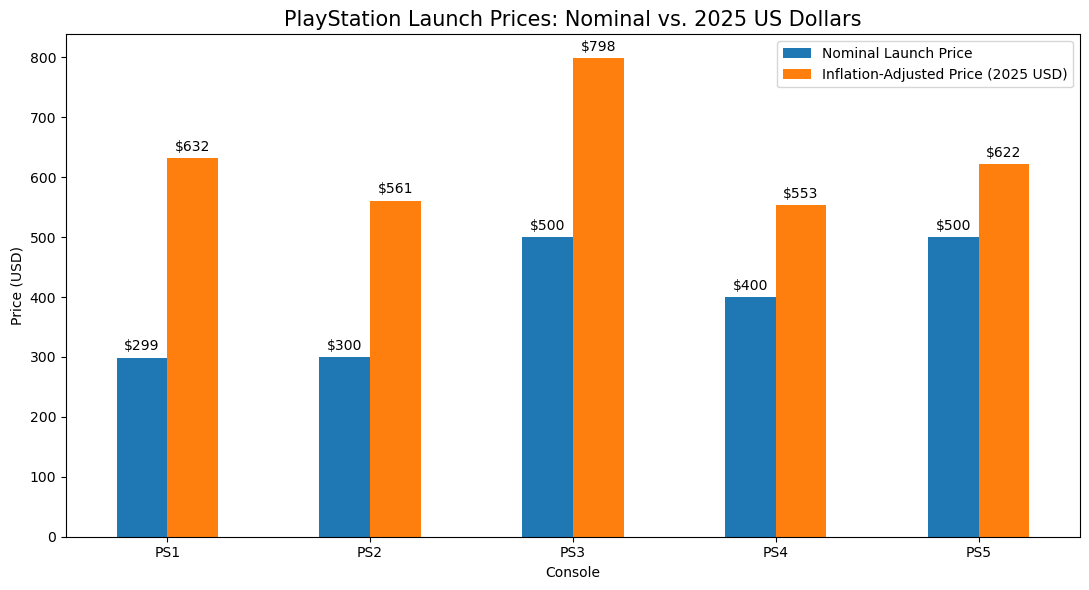

In [36]:
# Prepare nominal and inflation-adjusted prices for visualization
# Use Console as the chart's category index
plot_df = df.set_index("Console")[
    ["Launch Price", "Real_Price_2025"]
]

# Create a grouped bar chart comparing nominal and real launch prices
ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

# Add chart title and axis labels
ax.set_title(
    "PlayStation Launch Prices: Nominal vs. 2025 US Dollars",
    fontsize=15
)
ax.set_xlabel("Console")
ax.set_ylabel("Price (USD)")

# Replace variable names with reader-friendly legend labels
ax.legend([
    "Nominal Launch Price",
    "Inflation-Adjusted Price (2025 USD)"
])

# Keep console labels horizontal for readability
ax.tick_params(
    axis="x",
    rotation=0
)

# Add rounded dollar-value labels above each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.0f",
        padding=3
    )

# Improve spacing and prevent chart elements from being clipped
plt.tight_layout()

# Display the finished visualization
plt.show()

### Interpretation

The difierence between nominal and inflation-adjusted prices is particularly large for earlier PlayStation generations.

Although, as the PS1 launched for $299, its price is equivalent to 631.70 in 2025 U.S. Dollars.

This demonstrates why nominal prices from different periods should not be compared directly without considering inflation.

## 11. Real Launch Price by Generation

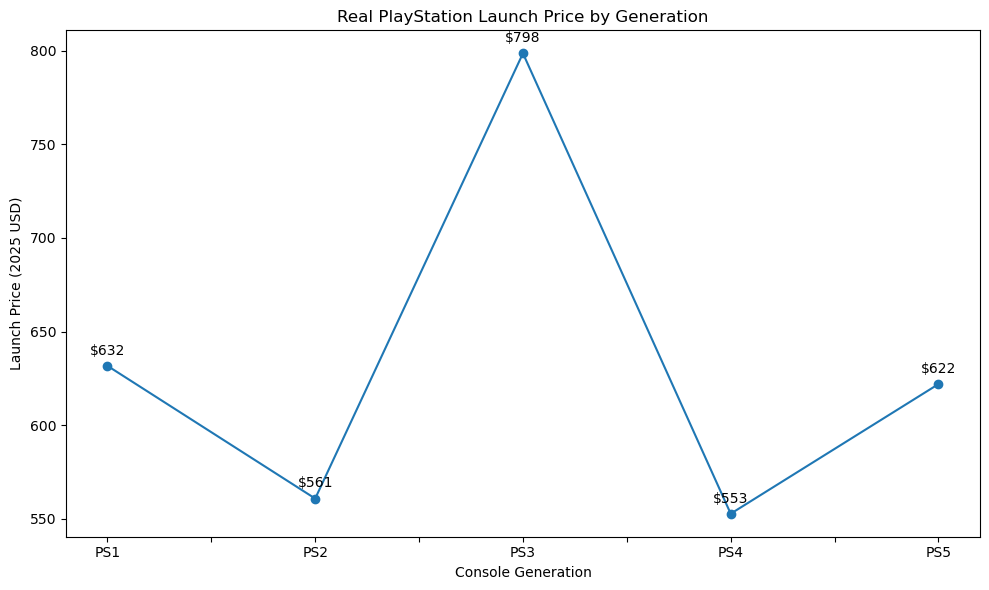

In [39]:
# Create a line chart showing inflation-adjusted prices
# These prices reflects across console generations
ax = df.plot(
    x="Console",
    y="Real_Price_2025",
    kind="line",
    marker="o",
    figsize=(10, 6),
    legend=False
)

# Add a descriptive chart title and axis labels
ax.set_title(
    "Real PlayStation Launch Price by Generation"
)

ax.set_xlabel("Console Generation")
ax.set_ylabel("Launch Price (2025 USD)")

# Add price labels using numeric x positions
for i, y in enumerate(df["Real_Price_2025"]):
    ax.annotate(
        f"${y:.0f}",
        xy=(i, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center"
    )

# Optimize spacing and display the visualization
plt.tight_layout()
plt.show()

### Interpretation

Inflation-adjusted PlayStation launch prices do not show a consistent upward trend.

Real prices declined from the PS1 to PS2; increased substantially with the PS3, then declined with the PS4 and increased again with
the PS5.

The PS3 represents the highest real launch price among the five console generations analyzed.

## 12. PS1 vs. PS5: A 25-Year Comparison

In [53]:
# Retrieve the PS1 inflation-adjusted launch price
ps1_real = df.loc[
    df["Console"] == "PS1",
    "Real_Price_2025"
].iloc[0]

# Retrieve the PS5 inflation-adjusted launch price
ps5_real = df.loc[
    df["Console"] == "PS5",
    "Real_Price_2025"
].iloc[0]

# Calculate the dollar difference between PS5 and PS1
difference = ps5_real - ps1_real

# Calculate the percentage difference using PS1 as the baseline
percent_difference = (
    (ps5_real / ps1_real) - 1
) * 100

# Display the comparison
print(f"Dollar difference: ${difference:.2f}")
print(f"Percentage difference: {percent_difference:.2f}%")

Dollar difference: $-9.75
Percentage difference: -1.54%


### Finding

The original PlayStation launched for $299 in 1995, while the
PS5 launched for 499.99 in 2020. 

However, after converting both prices to 2025 dollars, the PS1
launch price is approximately $631.70 compared with 621.95
for the PS5; resulting a difference of 9.75 U.S. dollars more than the PS5.

Therefore, despite a nominal price increase of more than $200,
the PS5 was approximately 1.5% less expensive than the PS1 in
inflation-adjusted terms.

# Key Findings

1. The PS3 was the most expensive PlayStation generation in real
   terms, with an inflation-adjusted launch price of approximately
   $798.49 in 2025 dollars.

2. The PS4 had the lowest real launch price at approximately
   $552.78.

3. The largest increase in real launch price occurred between the
   PS2 and PS3.

4. The largest decline occurred between the PS3 and PS4.

5. Despite launching at $499.99 compared with the PS1's 299,
   the PS5 was approximately 1.5% cheaper than the original
   PlayStation after adjusting for inflation.

6. Real PlayStation launch prices have fluctuated across
   generations rather than following a consistent upward trend.

# Limitations

CPI-U measures changes in the overall consumer price level rather
than changes specifically affecting video game consoles.

This analysis also does not account for differences in performance, income,
competition, quality, consumer preferences, etc.

Inflation-adjusted prices therefore measure changes in purchasing
cost and should not be interpreted as a direct measure of product
value or affordability.

# Conclusion

The analysis demonstrates that nominal PlayStation launch prices
can provide a misleading picture of long-term pricing trends.

After adjusting historical prices using CPI-U data, PlayStation
launch prices show substantial variation across generations rather
than a consistent increase.

The results also demonstrate that the PS5's higher nominal price
does not necessarily mean that it was historically more expensive.
In constant 2025 dollars, its launch price was slightly below that
of the original PlayStation.

This inflation-adjusted analysis provides additional economic
context for evaluating PlayStation's historical pricing strategy
and will be incorporated into the broader analysis of the
PlayStation console lifecycle and potential future-generation
scenarios.